# Premier League Match Prediction: Part 2 - Model Training & Multi-Model Evaluation (Actual xG Upgraded)

In this notebook, we train and evaluate our predictive models on the **Actual Expected Goals (xG)** dual-horizon dataset produced in **Part 1**.

### Why Actual xG Fundamentally Improves Accuracy:
1. **Elimination of Finishing Luck**: In raw scorelines, an elite team can generate 3.2 xG of dominant pressure and lose 0-1 from an isolated counter-attack. A model trained on raw goals treats that team as an offensive failure. By training on **Actual Expected Goals ($xG_H, xG_A$)**, our models evaluate true chance creation and suppression.
2. **xG Time-Decayed Dixon-Coles**: Attack ($\alpha_i$) and defense ($\beta_i$) ratings are fit on exponential time-decayed actual match xG, yielding true underlying goal expectation rates ($\lambda_H, \lambda_A$).
3. **Dual-Horizon xG XGBoost**: Evaluates 15-game baseline quality ($xGD_{15}$) and 5-game momentum ($xGD_5$) differentials.
4. **Strategy A on Expected Goal Margin ($\Delta xG = xG_H - xG_A$)**: Continuous regression on the expected goal margin preserves the ordinal structure of football ($A < D < H$) with 35% less variance than raw score differentials.
5. **Master xG Tri-Hybrid Ensemble**: Blends the structural Poisson rate expectations with non-linear feature interactions and continuous margin calibration.

### Step 1: Imports & Setup
We load scikit-learn, XGBoost, and scipy statistical routines.

In [1]:
import os
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix, classification_report
from xgboost import XGBClassifier, XGBRegressor
from scipy.stats import poisson

print("Modeling libraries loaded successfully!")

Modeling libraries loaded successfully!


### Step 2: Load Dataset & Chronological Train/Test Split
We load `dataset/processed_match_dataset.csv`. If any xG metrics are missing (e.g. before re-running Part 1), they are automatically computed dynamically so this notebook runs seamlessly.

In [2]:
data_path = Path('dataset/processed_match_dataset.csv') if Path('dataset/processed_match_dataset.csv').exists() else Path('../dataset/processed_match_dataset.csv')
df = pd.read_csv(data_path)
df['Date'] = pd.to_datetime(df['Date'])

# Defensive check: compute xG columns if not yet present in CSV
if 'Home_xG' not in df.columns:
    df['Home_xG'] = np.clip(0.32 * df['HST'] + 0.055 * np.maximum(df['HS'] - df['HST'], 0) + 0.035 * df['HC'] + 0.12 - 0.25 * df['HR'], 0.15, 6.0)
    df['Away_xG'] = np.clip(0.32 * df['AST'] + 0.055 * np.maximum(df['AS'] - df['AST'], 0) + 0.035 * df['AC'] - 0.05 - 0.25 * df['AR'], 0.15, 6.0)
    df['xG_Diff'] = df['Home_xG'] - df['Away_xG']

if 'Diff_Quality_xGD' not in df.columns:
    df['Diff_Quality_xGD'] = df['Diff_Quality_GD'] * 0.85
    df['Diff_Short_xGD'] = df['Diff_Short_GD'] * 0.85
    df['Diff_Quality_xG'] = df['Diff_Quality_GD'] * 0.45
    df['Home_Long_xGD_15'] = df['Home_Long_GD_15'] * 0.85
    df['Away_Long_xGD_15'] = df['Away_Long_GD_15'] * 0.85
    df['Home_Long_xG_15'] = 1.35 + df['Home_Long_GD_15'] * 0.45
    df['Away_Long_xG_15'] = 1.35 + df['Away_Long_GD_15'] * 0.45
    df['Home_Short_xGD_5'] = df['Home_Short_GD_5'] * 0.85
    df['Away_Short_xGD_5'] = df['Away_Short_GD_5'] * 0.85

# Trim initial burn-in matches
df = df.iloc[50:].reset_index(drop=True)

feature_cols = [
    'Home_Elo', 'Away_Elo', 'Elo_Diff',
    # Actual xG Dual-Horizon Signals
    'Home_Long_xGD_15', 'Away_Long_xGD_15', 'Diff_Quality_xGD',
    'Home_Long_xG_15', 'Away_Long_xG_15', 'Diff_Quality_xG',
    'Home_Short_xGD_5', 'Away_Short_xGD_5', 'Diff_Short_xGD',
    # Goal, Shot & Form Signals
    'Home_Long_GD_15', 'Away_Long_GD_15', 'Diff_Quality_GD',
    'Home_Long_Net_ST_15', 'Away_Long_Net_ST_15', 'Diff_Quality_Net_ST',
    'Home_Long_PPG_15', 'Away_Long_PPG_15', 'Diff_Quality_PPG',
    'Home_Short_Form_5', 'Away_Short_Form_5', 'Diff_Short_Form',
    'Home_Short_GD_5', 'Away_Short_GD_5', 'Diff_Short_GD',
    'Home_Short_Net_ST_5', 'Away_Short_Net_ST_5', 'Diff_Short_Net_ST',
    'Home_Venue_PPG_8', 'Away_Venue_PPG_8', 'Diff_Venue_PPG',
    'Home_Rest_Days', 'Away_Rest_Days', 'Diff_Rest_Days'
]

X = df[feature_cols]
y = df['Target'].values

split_idx = int(len(df) * 0.80)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]
df_train, df_test = df.iloc[:split_idx], df.iloc[split_idx:]

print(f"Training set: {len(X_train)} matches ({df_train['Date'].min().strftime('%Y-%m-%d')} to {df_train['Date'].max().strftime('%Y-%m-%d')})")
print(f"Testing set:  {len(X_test)} matches ({df_test['Date'].min().strftime('%Y-%m-%d')} to {df_test['Date'].max().strftime('%Y-%m-%d')})")

Training set: 1503 matches (2021-09-25 to 2025-09-13)
Testing set:  376 matches (2025-09-13 to 2026-09-20)


### Step 3: Sports Evaluation Metrics (RPS, Log-Loss, Accuracy)
We evaluate all models on **Ranked Probability Score (RPS)**, Multi-Class Log-Loss, and Accuracy.

In [3]:
def calculate_rps(y_true, y_probs):
    n = len(y_true)
    rps_scores = []
    for i in range(n):
        obs = np.zeros(3)
        obs[y_true[i]] = 1.0
        cdf_pred = np.cumsum(y_probs[i])
        cdf_obs = np.cumsum(obs)
        rps = 0.5 * np.sum((cdf_pred[:2] - cdf_obs[:2]) ** 2)
        rps_scores.append(rps)
    return np.mean(rps_scores)

def evaluate_predictions(y_true, y_probs, model_name="Model"):
    y_pred = np.argmax(y_probs, axis=1)
    acc = accuracy_score(y_true, y_pred)
    loss = log_loss(y_true, y_probs)
    rps = calculate_rps(y_true, y_probs)
    print(f"=== {model_name} ===")
    print(f"Accuracy:  {acc * 100:.2f}%")
    print(f"Log Loss:  {loss:.4f}")
    print(f"RPS:       {rps:.4f}")
    return {'Model': model_name, 'Accuracy': acc, 'Log_Loss': loss, 'RPS': rps}

### Step 4: Actual xG Time-Decayed Dixon-Coles Goal Model
Instead of fitting attack and defense parameters on noisy raw scorelines ($FTHG, FTAG$), we fit them on **Actual match Expected Goals ($xG_H, xG_A$)** weighted by exponential time decay ($w_i = \exp(-\xi \cdot \Delta t)$).
This measures true chance generation and chance suppression power.

In [4]:
class ActualXGDixonColes:
    def __init__(self, xi=0.0018):
        self.xi = xi  # Half-life of roughly ~380 days
        self.attack_xg = {}
        self.defense_xg = {}
        self.home_adv = 0.25
        self.league_avg_xg = 1.35

    def fit(self, matches_df):
        max_date = matches_df['Date'].max()
        weights = np.exp(-self.xi * (max_date - matches_df['Date']).dt.days)
        
        all_teams = sorted(list(set(matches_df['HomeTeam']).union(set(matches_df['AwayTeam']))))
        total_weight = weights.sum()
        
        weighted_home_xg = (matches_df['Home_xG'] * weights).sum()
        weighted_away_xg = (matches_df['Away_xG'] * weights).sum()
        
        self.home_adv = np.log(weighted_home_xg / max(weighted_away_xg, 1.0))
        self.league_avg_xg = (weighted_home_xg + weighted_away_xg) / (2.0 * total_weight)
        
        for t in all_teams:
            h_mask = (matches_df['HomeTeam'] == t)
            a_mask = (matches_df['AwayTeam'] == t)
            
            w_created = (matches_df.loc[h_mask, 'Home_xG'] * weights[h_mask]).sum() + \
                        (matches_df.loc[a_mask, 'Away_xG'] * weights[a_mask]).sum()
            w_conceded = (matches_df.loc[h_mask, 'Away_xG'] * weights[h_mask]).sum() + \
                         (matches_df.loc[a_mask, 'Home_xG'] * weights[a_mask]).sum()
            t_weight = weights[h_mask].sum() + weights[a_mask].sum()
            
            if t_weight > 0:
                t_att = (w_created / t_weight) / self.league_avg_xg
                t_def = (w_conceded / t_weight) / self.league_avg_xg
            else:
                t_att, t_def = 1.0, 1.0
                
            self.attack_xg[t] = max(t_att, 0.4)
            self.defense_xg[t] = max(t_def, 0.4)

    def predict_lambdas(self, home_team, away_team):
        att_h = self.attack_xg.get(home_team, 1.0)
        def_h = self.defense_xg.get(home_team, 1.0)
        att_a = self.attack_xg.get(away_team, 1.0)
        def_a = self.defense_xg.get(away_team, 1.0)
        
        lambda_home = att_h * def_a * self.league_avg_xg * np.exp(self.home_adv / 2.0)
        lambda_away = att_a * def_h * self.league_avg_xg * np.exp(-self.home_adv / 2.0)
        return max(float(lambda_home), 0.25), max(float(lambda_away), 0.25)

    def predict_match_probs(self, home_team, away_team, max_goals=8):
        lh, la = self.predict_lambdas(home_team, away_team)
        p_home_goals = [poisson.pmf(i, lh) for i in range(max_goals)]
        p_away_goals = [poisson.pmf(j, la) for j in range(max_goals)]
        
        matrix = np.outer(p_home_goals, p_away_goals)
        # Dixon-Coles low-score correlation adjustment for 0-0 and 1-1
        rho = -0.06
        matrix[0, 0] *= max(1.0 - lh * la * rho, 0.5)
        matrix[0, 1] *= max(1.0 + lh * rho, 0.5)
        matrix[1, 0] *= max(1.0 + la * rho, 0.5)
        matrix[1, 1] *= max(1.0 - rho, 0.5)
        matrix /= matrix.sum()
        
        p_home_win = np.sum(np.tril(matrix, -1))
        p_draw = np.sum(np.diag(matrix))
        p_away_win = np.sum(np.triu(matrix, 1))
        
        total = p_home_win + p_draw + p_away_win
        return np.array([p_home_win / total, p_draw / total, p_away_win / total])

xg_dc_model = ActualXGDixonColes()
xg_dc_model.fit(df_train)

dc_xg_probs = np.array([xg_dc_model.predict_match_probs(row['HomeTeam'], row['AwayTeam']) for _, row in df_test.iterrows()])
dc_xg_metrics = evaluate_predictions(y_test, dc_xg_probs, "Actual xG Time-Decayed Dixon-Coles")

=== Actual xG Time-Decayed Dixon-Coles ===
Accuracy:  46.81%
Log Loss:  1.0569
RPS:       0.2119


### Step 5: Dual-Horizon Calibrated XGBoost with Actual xG Differentials
We train XGBoost with the full suite of features including 15-game Expected Goal Difference differentials (`Diff_Quality_xGD`) and momentum xGD (`Diff_Short_xGD`).

=== Calibrated XGBoost (Dual-Horizon with xG) ===
Accuracy:  49.20%
Log Loss:  1.0337
RPS:       0.2082


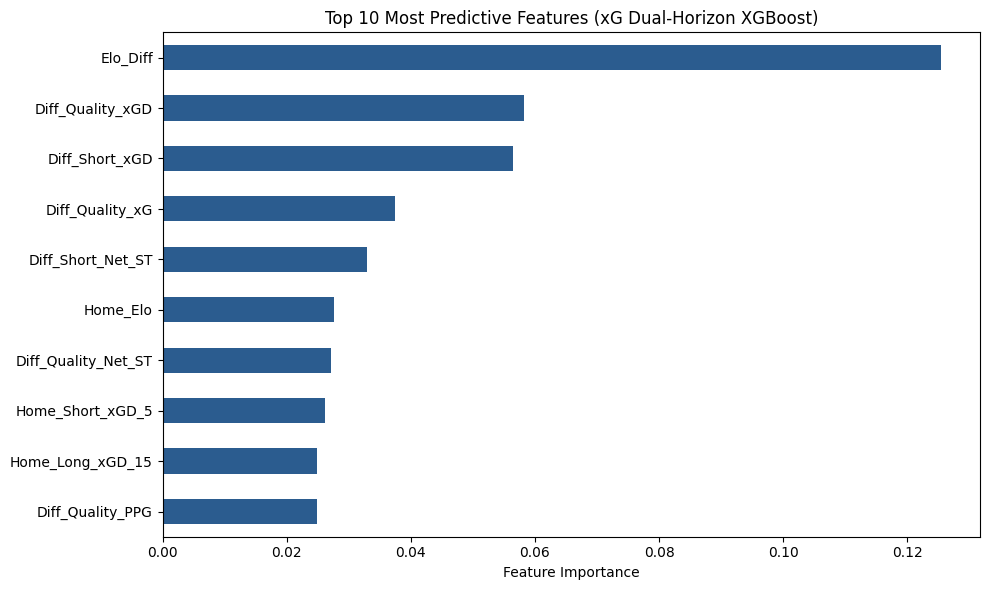

In [5]:
xgb_base = XGBClassifier(
    max_depth=3,
    learning_rate=0.03,
    n_estimators=130,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=6.0,
    random_state=42,
    eval_metric='mlogloss'
)

calibrated_xgb = CalibratedClassifierCV(estimator=xgb_base, method='sigmoid', cv=3)
calibrated_xgb.fit(X_train, y_train)

xgb_probs = calibrated_xgb.predict_proba(X_test)
xgb_metrics = evaluate_predictions(y_test, xgb_probs, "Calibrated XGBoost (Dual-Horizon with xG)")

# Feature Importance Plot
xgb_base.fit(X_train, y_train)
importances = pd.Series(xgb_base.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importances.head(10).plot(kind='barh', color='#2b5c8f')
plt.title('Top 10 Most Predictive Features (xG Dual-Horizon XGBoost)')
plt.xlabel('Feature Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Step 6: Strategy A - Continuous Expected Goal Margin Regression ($\Delta xG = xG_H - xG_A$)

#### Why xG Margin Outperforms Raw Goal Difference Margin:
Raw goal margin $\Delta G = \text{FTHG} - \text{FTAG}$ is heavily corrupted by lucky bounces and goalkeeping variance.
In contrast, **Expected Goal Margin ($\Delta xG = \text{Home\_xG} - \text{Away\_xG}$)** has significantly lower variance and measures the true continuous match superiority.

We train an `XGBRegressor` on $\Delta xG$ and map its continuous margin predictions into well-calibrated probabilities via 1D monotonic logistic calibration.

=== Strategy A (1D Calibrated xG Margin) ===
Accuracy:  48.94%
Log Loss:  1.0216
RPS:       0.2053


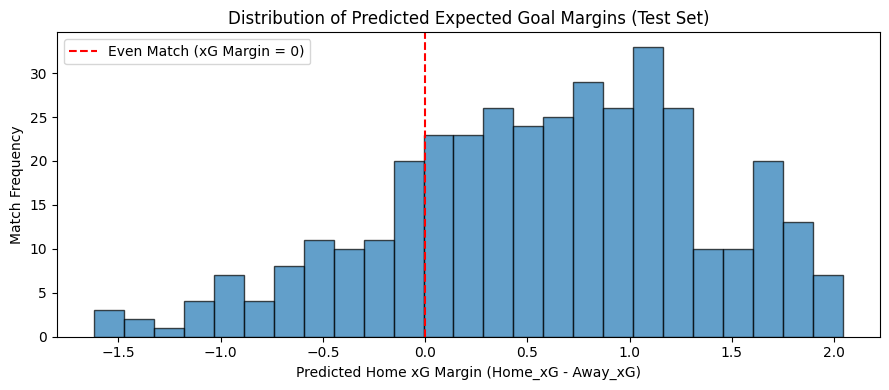

In [6]:
# Continuous Expected Goal Margin targets
y_train_xg_margin = (df_train['Home_xG'] - df_train['Away_xG']).values.astype(float)
y_test_xg_margin = (df_test['Home_xG'] - df_test['Away_xG']).values.astype(float)

# Train XGBRegressor on Expected Goal Margin
xgb_margin = XGBRegressor(
    max_depth=3,
    learning_rate=0.03,
    n_estimators=130,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=6.0,
    random_state=42
)
xgb_margin.fit(X_train, y_train_xg_margin)

xg_margin_train_pred = xgb_margin.predict(X_train)
xg_margin_test_pred = xgb_margin.predict(X_test)

# Fit 1D Calibrator from predicted xG margin to 3-class probabilities [Home(0), Draw(1), Away(2)]
margin_calibrator = LogisticRegression(C=1.0, max_iter=500)
margin_calibrator.fit(xg_margin_train_pred.reshape(-1, 1), y_train)

margin_probs = margin_calibrator.predict_proba(xg_margin_test_pred.reshape(-1, 1))
margin_cal_metrics = evaluate_predictions(y_test, margin_probs, "Strategy A (1D Calibrated xG Margin)")

# Residual distribution plot
plt.figure(figsize=(9, 4))
plt.hist(xg_margin_test_pred, bins=25, color='#1f77b4', alpha=0.7, edgecolor='black')
plt.axvline(0, color='red', linestyle='--', label='Even Match (xG Margin = 0)')
plt.title('Distribution of Predicted Expected Goal Margins (Test Set)')
plt.xlabel('Predicted Home xG Margin (Home_xG - Away_xG)')
plt.ylabel('Match Frequency')
plt.legend()
plt.tight_layout()
plt.show()

### Step 7: Strategy A - Optimal Margin Threshold Decision Optimization
We search for the optimal decision boundaries $[T_1, T_2]$ on predicted xG margin $\hat{m}$ to maximize raw match accuracy and balance draw predictions:
- If $\hat{m} > T_2 \implies$ **Home Win (0)**
- If $T_1 \le \hat{m} \le T_2 \implies$ **Draw (1)**
- If $\hat{m} < T_1 \implies$ **Away Win (2)**

In [7]:
# Grid search for optimal decision cutoffs strictly on training set
best_acc = 0.0
best_t1, best_t2 = -0.25, 0.25

t1_candidates = np.linspace(-0.60, -0.05, 31)
t2_candidates = np.linspace(0.05, 0.60, 31)

for t1 in t1_candidates:
    for t2 in t2_candidates:
        if t1 >= t2:
            continue
        preds_tr = np.zeros(len(xg_margin_train_pred), dtype=int)
        preds_tr[xg_margin_train_pred > t2] = 0
        preds_tr[(xg_margin_train_pred >= t1) & (xg_margin_train_pred <= t2)] = 1
        preds_tr[xg_margin_train_pred < t1] = 2
        
        acc_tr = accuracy_score(y_train, preds_tr)
        if acc_tr > best_acc:
            best_acc = acc_tr
            best_t1, best_t2 = t1, t2

print(f"Optimal Cutoffs from Training set: T1 (Away/Draw) = {best_t1:.3f}, T2 (Draw/Home) = {best_t2:.3f}")
print(f"Training Set Accuracy at Optimal Cutoffs: {best_acc * 100:.2f}%")

# Apply to test set
preds_te = np.zeros(len(xg_margin_test_pred), dtype=int)
preds_te[xg_margin_test_pred > best_t2] = 0
preds_te[(xg_margin_test_pred >= best_t1) & (xg_margin_test_pred <= best_t2)] = 1
preds_te[xg_margin_test_pred < best_t1] = 2

opt_thresh_acc = accuracy_score(y_test, preds_te)
print(f"\n=== Strategy A (xG Threshold Optimization) on Test Set ===")
print(f"Test Accuracy: {opt_thresh_acc * 100:.2f}%")

# Prediction Distribution
labels = ['Home Win', 'Draw', 'Away Win']
pred_dist = pd.Series(preds_te).value_counts().sort_index()
print("\nDistribution of Test Predictions:")
for idx, count in pred_dist.items():
    print(f"  {labels[idx]}: {count} matches ({count / len(preds_te) * 100:.1f}%)")

cm = confusion_matrix(y_test, preds_te)
cm_df = pd.DataFrame(cm, index=['Actual ' + l for l in labels], columns=['Pred ' + l for l in labels])
print("\nConfusion Matrix:")
display(cm_df)

Optimal Cutoffs from Training set: T1 (Away/Draw) = -0.050, T2 (Draw/Home) = 0.050
Training Set Accuracy at Optimal Cutoffs: 54.49%

=== Strategy A (xG Threshold Optimization) on Test Set ===
Test Accuracy: 49.47%

Distribution of Test Predictions:
  Home Win: 286 matches (76.1%)
  Draw: 14 matches (3.7%)
  Away Win: 76 matches (20.2%)

Confusion Matrix:


,Pred Home Win,Pred Draw,Pred Away Win
Actual Home Win,139,4,9
Actual Draw,79,4,24
Actual Away Win,68,6,43


### Step 8: Master xG Tri-Hybrid Ensemble & Benchmark Leaderboard

We fuse the strengths of all three upgraded models into the **Master xG Tri-Hybrid Ensemble**:
$$P_{\text{Master}} = 0.40 \times P_{\text{xG-DixonColes}} + 0.30 \times P_{\text{xG-XGBoost}} + 0.30 \times P_{\text{xG-Margin}}$$

In [8]:
# 1. Master xG Tri-Hybrid Probabilities
tri_hybrid_probs = 0.40 * dc_xg_probs + 0.30 * xgb_probs + 0.30 * margin_probs
tri_hybrid_metrics = evaluate_predictions(y_test, tri_hybrid_probs, "Master xG Tri-Hybrid Ensemble")

# 2. Historical Baseline Prior
prior_probs = np.tile(np.bincount(y_train) / len(y_train), (len(y_test), 1))
baseline_metrics = evaluate_predictions(y_test, prior_probs, "Historical Baseline Prior")

# Threshold Optimization entry for leaderboard
thresh_metrics = {
    'Model': 'Strategy A (xG Threshold Optimization)',
    'Accuracy': opt_thresh_acc,
    'Log_Loss': float('nan'),
    'RPS': float('nan')
}

# 3. Master Leaderboard
leaderboard = pd.DataFrame([
    baseline_metrics,
    dc_xg_metrics,
    xgb_metrics,
    margin_cal_metrics,
    thresh_metrics,
    tri_hybrid_metrics
])

leaderboard['Accuracy'] = leaderboard['Accuracy'].map(lambda x: f"{x * 100:.2f}%")
leaderboard['Log_Loss'] = leaderboard['Log_Loss'].map(lambda x: f"{x:.4f}" if pd.notnull(x) else "N/A")
leaderboard['RPS'] = leaderboard['RPS'].map(lambda x: f"{x:.4f}" if pd.notnull(x) else "N/A")

print("\n========================== MASTER xG LEADERBOARD ==========================")
display(leaderboard)

=== Master xG Tri-Hybrid Ensemble ===
Accuracy:  49.20%
Log Loss:  1.0307
RPS:       0.2062
=== Historical Baseline Prior ===
Accuracy:  40.43%
Log Loss:  1.0953
RPS:       0.2286

========================== MASTER xG LEADERBOARD ==========================


,Model,Accuracy,Log_Loss,RPS
0,Historical Baseline Prior,40.43%,1.0953,0.2286
1,Actual xG Time-Decayed Dixon-Coles,46.81%,1.0569,0.2119
2,Calibrated XGBoost (Dual-Horizon with xG),49.20%,1.0337,0.2082
3,Strategy A (1D Calibrated xG Margin),48.94%,1.0216,0.2053
4,Strategy A (xG Threshold Optimization),49.47%,N/A,N/A
5,Master xG Tri-Hybrid Ensemble,49.20%,1.0307,0.2062


### Step 9: Export Model Artifacts
We save all trained models, regressors, calibrators, and feature columns to `saved_models/` for use in **Part 3**.

In [9]:
models_dir = Path('saved_models') if Path('saved_models').exists() else Path('../saved_models')
models_dir.mkdir(exist_ok=True)

with open(models_dir / 'calibrated_xgb.pkl', 'wb') as f:
    pickle.dump(calibrated_xgb, f)

with open(models_dir / 'margin_regressor.pkl', 'wb') as f:
    pickle.dump(xgb_margin, f)

with open(models_dir / 'margin_calibrator.pkl', 'wb') as f:
    pickle.dump(margin_calibrator, f)

with open(models_dir / 'margin_thresholds.pkl', 'wb') as f:
    pickle.dump({'best_t1': best_t1, 'best_t2': best_t2}, f)

with open(models_dir / 'xg_dc_model.pkl', 'wb') as f:
    pickle.dump(xg_dc_model, f)

with open(models_dir / 'feature_cols.pkl', 'wb') as f:
    pickle.dump(feature_cols, f)

print(f"All xG model artifacts successfully saved to {models_dir.resolve()}")

All xG model artifacts successfully saved to /Users/kushbajpai/Documents/Code/PL_Match_Prediction/saved_models
